<div dir="rtl">

# مشروع صغير: تحليل طلبات مطعم بمساعدة الذكاء الاصطناعي
**السؤال الرئيسي:** أين تربح إدارة المطعم، ومتى يزدحم، وما الذي يُغضب العملاء؟

**البيانات:** `restaurant_orders.csv` (طلبات 3 فروع، يناير إلى يونيو 2025). اقرأ `data_dictionary_restaurant.md` أولًا.

**المهارات المستخدمة في Cursor:** `/data-quality-report` ← `/kpi-summary` ← `/clear-charts` ← `/insight-report`

**طريقة العمل:** لكل سؤال: اطلب من Agent الكود (أو استدعِ المهارة)، اقرأ الكود قبل قبوله، شغّله، ثم قارن بنقطة التحقق.

</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# نقرأ المصدر الأصلي دون تعديله
orders = pd.read_csv("restaurant_orders.csv")
print(f"حجم الملف: {orders.shape[0]} صفًا و{orders.shape[1]} عمودًا")
orders.head()

حجم الملف: 1515 صفًا و12 عمودًا


,order_id,order_date,order_hour,branch,channel,category,item,quantity,unit_price,total,delivery_minutes,rating
0,R10001,2025-01-01,11,Downtown,Delivery,Sides,Hummus,5,3.5,17.5,43.0,3.0
1,R10002,2025-01-01,19,Mall,Takeaway,Main,Falafel Wrap,4,4.5,18.0,NaN,4.0
2,R10003,2025-01-01,20,Downtown,Dine-in,Main,Chicken Shawarma,3,6.5,19.5,NaN,NaN
3,R10004,2025-01-01,22,University,Delivery,Main,Beef Burger,2,8.0,16.0,28.0,5.0
4,R10005,2025-01-02,11,Mall,Delivery,Drinks,Fresh Juice,3,3.0,9.0,29.0,4.0


<div dir="rtl">

## الخطوة 1: فحص الجودة والتنظيف
في Agent: `/data-quality-report افحص restaurant_orders.csv` ثم: «نظّف البيانات حسب التقرير واحفظها في clean».

**نقطة تحقق:** 15 صفًا مكررًا، و6 كتابات مختلفة لأسماء الفروع، و136 تقييمًا مفقودًا. بعد التنظيف: **1500 صف** و3 فروع فقط.

</div>

In [2]:
# نفحص جودة البيانات باستخدام pandas دون تعديل الملف الأصلي
# نعرض عدد الصفوف والأعمدة وأنواعها والقيم المفقودة والتكرارات
print(f"الحجم: {orders.shape[0]} صفًا و{orders.shape[1]} عمودًا")
print("أنواع الأعمدة:\n", orders.dtypes.to_string())
missing = orders.isna().sum()
print("\nالقيم المفقودة في كل عمود:\n", missing.to_string())
duplicates = int(orders.duplicated().sum())
print(f"\nالصفوف المكررة بالكامل: {duplicates}")

# نستعرض القيم المختلفة للأعمدة النصية ذات أقل من 20 فئة
text_columns = orders.select_dtypes(include=["object", "string"]).columns
categories = {}
for column in text_columns:
    if orders[column].nunique(dropna=True) < 20:
        categories[column] = sorted(orders[column].dropna().astype(str).unique())
        print(f"\nالقيم المختلفة في {column}: {categories[column]}")

# نعرض أصغر وأكبر قيمة في كل عمود رقمي وننبه إلى السوالب
numeric_columns = orders.select_dtypes(include="number").columns
negative_counts = {}
for column in numeric_columns:
    negative_counts[column] = int(orders[column].lt(0).sum())
    print(f"{column}: الأدنى={orders[column].min()}, الأعلى={orders[column].max()}, القيم السالبة={negative_counts[column]}")

# نلخص المشكلات؛ غياب مدة التوصيل لغير طلبات التوصيل طبيعي
issues = []
for column, count in missing.items():
    if count and column != "delivery_minutes":
        treatment = "الإبقاء على الصفوف واستبعاد التقييمات المفقودة عند حساب المتوسط" if column == "rating" else "التحقق من المصدر قبل اختيار المعالجة"
        issues.append(["قيم مفقودة", column, int(count), treatment])
if duplicates:
    issues.append(["صفوف مكررة بالكامل", "جميع الأعمدة", duplicates, "مراجعة الصفوف وحذف النسخ المتطابقة بعد التأكد"])
if "branch" in categories and len(categories["branch"]) > 3:
    branch_variant_count = len(categories["branch"])
    branch_rows_to_normalize = int(orders["branch"].ne(orders["branch"].str.strip().str.title()).sum())
    issues.append([f"اختلاف كتابة أسماء الفروع ({branch_variant_count} صيغ)", "branch", branch_rows_to_normalize, "إزالة المسافات وتوحيد حالة الأحرف وربطها بالأسماء المعتمدة"])
for column, count in negative_counts.items():
    if count:
        issues.append(["قيم سالبة تحتاج إلى التحقق", column, count, "التحقق من المصدر وتصحيح القيم عند ثبوت الخطأ"])

report = pd.DataFrame(issues, columns=["المشكلة", "العمود", "عدد الصفوف", "اقتراح المعالجة"])
print("\nتقرير جودة البيانات:")
display(report if not report.empty else "لم تُكتشف مشكلات وفق الفحوص المنفذة.")


الحجم: 1515 صفًا و12 عمودًا
أنواع الأعمدة:
 order_id                str
order_date              str
order_hour            int64
branch                  str
channel                 str
category                str
item                    str
quantity              int64
unit_price          float64
total               float64
delivery_minutes    float64
rating              float64

القيم المفقودة في كل عمود:
 order_id               0
order_date             0
order_hour             0
branch                 0
channel                0
category               0
item                   0
quantity               0
unit_price             0
total                  0
delivery_minutes    1137
rating               136

الصفوف المكررة بالكامل: 15

القيم المختلفة في branch: [' downtown', ' mall', ' university', 'DOWNTOWN', 'Downtown', 'MALL', 'Mall', 'UNIVERSITY', 'University']

القيم المختلفة في channel: ['Delivery', 'Dine-in', 'Takeaway']

القيم المختلفة في category: ['Dessert', 'Drinks', 'Main', 'Sides'

,المشكلة,العمود,عدد الصفوف,اقتراح المعالجة
0,قيم مفقودة,rating,136,الإبقاء على الصفوف واستبعاد التقييمات المفقودة...
1,صفوف مكررة بالكامل,جميع الأعمدة,15,مراجعة الصفوف وحذف النسخ المتطابقة بعد التأكد
2,اختلاف كتابة أسماء الفروع (9 صيغ),branch,24,إزالة المسافات وتوحيد حالة الأحرف وربطها بالأس...


In [3]:
# ننشئ نسخة تحليلية؛ نحذف التطابق الكامل فقط ونوحّد أسماء الفروع
clean = orders.drop_duplicates().copy()
clean["branch"] = clean["branch"].str.strip().str.title()
clean["order_date"] = pd.to_datetime(clean["order_date"], errors="raise")

print(f"الصفوف الأصلية: {len(orders):,}")
print(f"الصفوف المتطابقة بالكامل: {int(orders.duplicated().sum()):,}")
print(f"الصفوف بعد حذف التطابق الكامل: {len(clean):,}")
print(f"صيغ الفروع بعد التوحيد: {sorted(clean['branch'].unique())}")
print(f"التقييمات المفقودة بعد التنظيف: {int(clean['rating'].isna().sum()):,} (دون تعويض)")
print(f"صفوف الأصناف: {len(clean):,}؛ أرقام الطلبات الفريدة: {clean['order_id'].nunique():,}")
print(f"أرقام الطلبات التي تضم أكثر من صنف: {int(clean.groupby('order_id').size().gt(1).sum()):,}")

# نتحقق أن الحذف اقتصر على التطابق الكامل وبقيت التقييمات المفقودة كما هي
assert len(orders) - len(clean) == int(orders.duplicated().sum())
assert clean["rating"].isna().sum() == orders.drop_duplicates()["rating"].isna().sum()
assert set(clean["branch"].unique()) == {"Downtown", "Mall", "University"}

# نتحقق أن حقول الطلب الثابتة لا تختلف بين صفوف أصنافه
order_fields = ["order_date", "order_hour", "branch", "channel", "delivery_minutes", "rating"]
inconsistent_orders = clean.groupby("order_id")[order_fields].nunique(dropna=False).gt(1).any(axis=1)
print(f"الطلبات ذات بيانات متعارضة بين صفوفها: {int(inconsistent_orders.sum()):,}")
assert not inconsistent_orders.any()


الصفوف الأصلية: 1,515
الصفوف المتطابقة بالكامل: 15
الصفوف بعد حذف التطابق الكامل: 1,500
صيغ الفروع بعد التوحيد: ['Downtown', 'Mall', 'University']
التقييمات المفقودة بعد التنظيف: 132 (دون تعويض)
صفوف الأصناف: 1,500؛ أرقام الطلبات الفريدة: 1,500
أرقام الطلبات التي تضم أكثر من صنف: 0
الطلبات ذات بيانات متعارضة بين صفوفها: 0


<div dir="rtl">

## الخطوة 2: مؤشرات الأداء (س1)
**س1:** ما إجمالي الإيرادات وعدد الطلبات ومتوسط قيمة الطلب ومتوسط التقييم؟ وما هي لكل فرع؟

في Agent: `/kpi-summary احسب المؤشرات العامة ثم قارن الفروع`

</div>

In [4]:
# نلخص كل طلب مرة واحدة حتى لا نعد صفوف الأصناف كطلبات متعددة
order_level = clean.groupby("order_id", as_index=False).agg(
    order_date=("order_date", "first"),
    order_hour=("order_hour", "first"),
    branch=("branch", "first"),
    channel=("channel", "first"),
    delivery_minutes=("delivery_minutes", "first"),
    rating=("rating", "first"),
    order_revenue=("total", "sum"),
)
total_revenue = clean["total"].sum()
total_orders = order_level["order_id"].nunique()
overall_aov = total_revenue / total_orders

branch_metrics = clean.groupby("branch").agg(
    revenue=("total", "sum"),
    orders=("order_id", "nunique"),
)
branch_metrics["average_order_value"] = branch_metrics["revenue"] / branch_metrics["orders"]
branch_metrics["average_rating"] = order_level.groupby("branch")["rating"].mean()
branch_metrics["revenue_share_pct"] = branch_metrics["revenue"] / total_revenue * 100
branch_metrics = branch_metrics.sort_values("revenue", ascending=False)

print("المؤشرات العامة:")
display(pd.DataFrame({
    "الإيرادات ($)": [total_revenue],
    "الطلبات الفريدة": [total_orders],
    "متوسط قيمة الطلب ($)": [overall_aov],
    "متوسط التقييم": [order_level["rating"].mean()],
}).round(2))

print("المؤشرات حسب الفرع:")
branch_table = branch_metrics.rename(columns={
    "revenue": "الإيرادات ($)",
    "orders": "عدد الطلبات",
    "average_order_value": "متوسط قيمة الطلب ($)",
    "average_rating": "متوسط التقييم",
    "revenue_share_pct": "حصة الإيرادات %",
})
display(branch_table.round(2))
assert round(branch_metrics["revenue"].sum(), 2) == round(total_revenue, 2)
assert int(branch_metrics["orders"].sum()) == total_orders

highest_branch = branch_metrics["revenue"].idxmax()
lowest_branch = branch_metrics["revenue"].idxmin()
print(f"أعلى فرع إيرادًا: {highest_branch} ({branch_metrics.loc[highest_branch, 'revenue']:.2f})")
print(f"أقل فرع إيرادًا: {lowest_branch} ({branch_metrics.loc[lowest_branch, 'revenue']:.2f})")
print(f"فارق الإيراد بينهما: {branch_metrics['revenue'].max() - branch_metrics['revenue'].min():.2f}")


المؤشرات العامة:


,الإيرادات ($),الطلبات الفريدة,متوسط قيمة الطلب ($),متوسط التقييم
0,18751.0,1500,12.5,4.07


المؤشرات حسب الفرع:


,الإيرادات ($),عدد الطلبات,متوسط قيمة الطلب ($),متوسط التقييم,حصة الإيرادات %
branch,,,,,
Mall,7933.0,590,13.45,4.12,42.31
Downtown,6678.0,466,14.33,4.01,35.61
University,4140.0,444,9.32,4.04,22.08


أعلى فرع إيرادًا: Mall (7933.00)
أقل فرع إيرادًا: University (4140.00)
فارق الإيراد بينهما: 3793.00


<div dir="rtl">

## الخطوة 3: الذروة والقنوات والأصناف (س2، س3، س4)
- **س2:** ما ساعات الذروة؟ وأي أيام الأسبوع أكثر ازدحامًا؟
- **س3:** ما حصة كل قناة (صالة، سفري، توصيل) من الإيرادات؟
- **س4:** ما أعلى 5 أصناف من حيث الإيرادات؟

ارسم رسمين على الأقل باستخدام `/clear-charts`.

</div>

الطلبات حسب يوم الأسبوع:


,عدد الطلبات
weekday,
الاثنين,204
الثلاثاء,179
الأربعاء,180
الخميس,197
الجمعة,278
السبت,280
الأحد,182


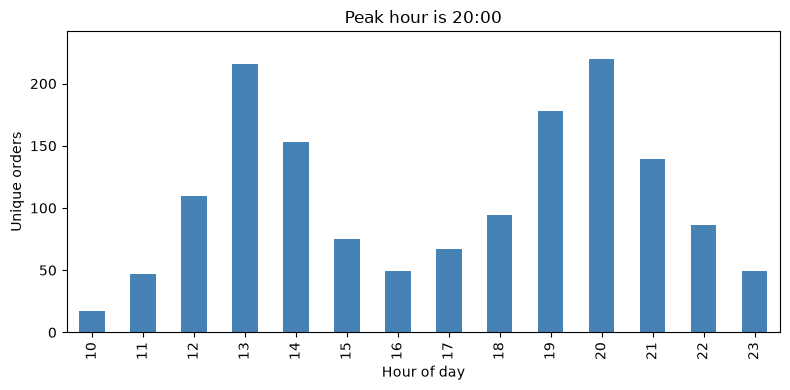

,عدد الطلبات
order_hour,
10,17
11,47
12,110
13,216
14,153
15,75
16,49
17,67
18,94


أكثر ساعة ازدحامًا: 20:00 بعدد 220 طلبًا فريدًا.


In [5]:
# نعد الطلبات الفريدة لكل ساعة ولكل يوم في الأسبوع
hour_counts = order_level.groupby("order_hour")["order_id"].nunique().sort_index()
weekday_names = ["الاثنين", "الثلاثاء", "الأربعاء", "الخميس", "الجمعة", "السبت", "الأحد"]
weekday_counts = (
    order_level.assign(weekday=order_level["order_date"].dt.dayofweek)
    .groupby("weekday")["order_id"].nunique()
    .reindex(range(7), fill_value=0)
)
weekday_chart = weekday_counts.rename(index=dict(enumerate(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])))
weekday_table = weekday_counts.rename(index=dict(enumerate(weekday_names))).rename("عدد الطلبات").to_frame()
print("الطلبات حسب يوم الأسبوع:")
display(weekday_table)

# نرسم عدد الطلبات الفريدة حسب الساعة
fig, ax = plt.subplots(figsize=(8, 4))
hour_counts.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title(f"Peak hour is {int(hour_counts.idxmax())}:00")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Unique orders")
ax.set_ylim(0, hour_counts.max() * 1.1)
plt.tight_layout()
plt.show()
display(hour_counts.rename("عدد الطلبات").to_frame())
peak_hour = int(hour_counts.idxmax())
print(f"أكثر ساعة ازدحامًا: {peak_hour}:00 بعدد {int(hour_counts.loc[peak_hour])} طلبًا فريدًا.")


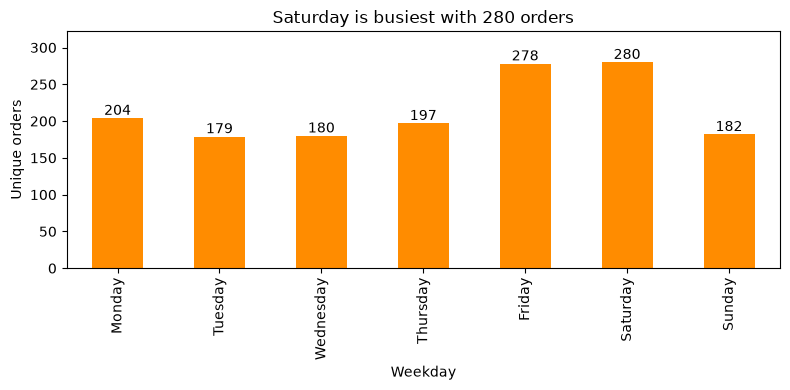

,عدد الطلبات
weekday,
الاثنين,204
الثلاثاء,179
الأربعاء,180
الخميس,197
الجمعة,278
السبت,280
الأحد,182


أكثر أيام الأسبوع ازدحامًا: السبت بعدد 280 طلبًا.


In [6]:
# نرسم عدد الطلبات حسب أيام الأسبوع بالترتيب
fig, ax = plt.subplots(figsize=(8, 4))
weekday_chart.plot(kind="bar", ax=ax, color="darkorange")
ax.set_title(f"{weekday_chart.idxmax()} is busiest with {int(weekday_chart.max())} orders")
ax.set_xlabel("Weekday")
ax.set_ylabel("Unique orders")
ax.set_ylim(0, weekday_counts.max() * 1.15)
for bar in ax.patches:
    ax.annotate(f"{bar.get_height():.0f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.show()
display(weekday_table)
busiest_weekday = int(weekday_counts.idxmax())
print(f"أكثر أيام الأسبوع ازدحامًا: {weekday_names[busiest_weekday]} بعدد {int(weekday_counts.loc[busiest_weekday])} طلبًا.")


حصة قنوات البيع من الإيرادات:


,القناة,الإيرادات ($),حصة الإيرادات %
1,Dine-in,8122.0,43.32
2,Takeaway,5459.0,29.11
0,Delivery,5170.0,27.57


أعلى خمسة أصناف إيرادًا:


,الصنف,الإيرادات ($)
11,Mixed Grill,4864.0
7,Grilled Chicken Plate,3399.0
0,Beef Burger,2464.0
1,Chicken Shawarma,1878.5
3,Falafel Wrap,1314.0


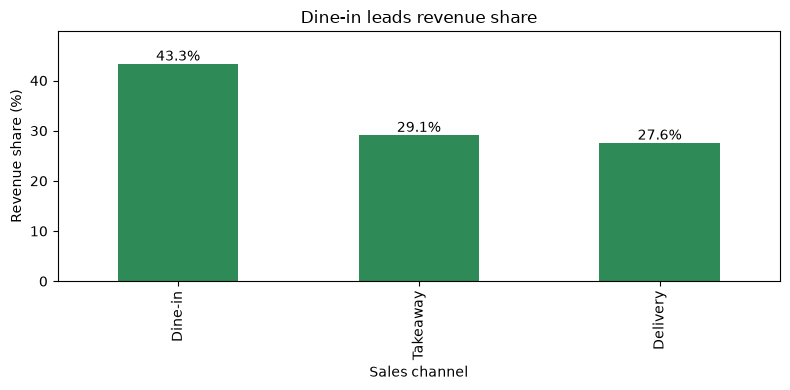

,القناة,الإيرادات ($),حصة الإيرادات %
1,Dine-in,8122.0,43.32
2,Takeaway,5459.0,29.11
0,Delivery,5170.0,27.57


القناة الأعلى إيرادًا: Dine-in بحصة 43.32%.


In [7]:
# نحسب إيرادات القنوات وحصتها من إجمالي الإيرادات
channel_metrics = clean.groupby("channel", as_index=False).agg(revenue=("total", "sum"))
channel_metrics["revenue_share_pct"] = channel_metrics["revenue"] / total_revenue * 100
channel_metrics = channel_metrics.sort_values("revenue", ascending=False)
print("حصة قنوات البيع من الإيرادات:")
display(channel_metrics.rename(columns={"channel": "القناة", "revenue": "الإيرادات ($)", "revenue_share_pct": "حصة الإيرادات %"}).round(2))
assert round(channel_metrics["revenue"].sum(), 2) == round(total_revenue, 2)

# نرتب الأصناف بحسب مجموع قيمة مبيعاتها
top_items = clean.groupby("item", as_index=False).agg(revenue=("total", "sum")).nlargest(5, "revenue")
print("أعلى خمسة أصناف إيرادًا:")
display(top_items.rename(columns={"item": "الصنف", "revenue": "الإيرادات ($)"}).round(2))

# نرسم حصة القنوات من الإيرادات
fig, ax = plt.subplots(figsize=(8, 4))
channel_metrics.plot(kind="bar", x="channel", y="revenue_share_pct", ax=ax, legend=False, color="seagreen")
ax.set_title(f"{channel_metrics.iloc[0]['channel']} leads revenue share")
ax.set_xlabel("Sales channel")
ax.set_ylabel("Revenue share (%)")
ax.set_ylim(0, channel_metrics["revenue_share_pct"].max() * 1.15)
for bar in ax.patches:
    ax.annotate(f"{bar.get_height():.1f}%", (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.show()
display(channel_metrics.rename(columns={"channel": "القناة", "revenue": "الإيرادات ($)", "revenue_share_pct": "حصة الإيرادات %"}).round(2))
print(f"القناة الأعلى إيرادًا: {channel_metrics.iloc[0]['channel']} بحصة {channel_metrics.iloc[0]['revenue_share_pct']:.2f}%.")


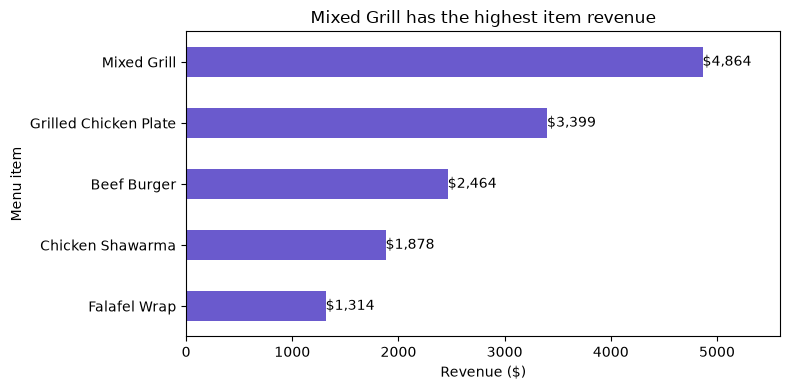

,الصنف,الإيرادات ($)
11,Mixed Grill,4864.0
7,Grilled Chicken Plate,3399.0
0,Beef Burger,2464.0
1,Chicken Shawarma,1878.5
3,Falafel Wrap,1314.0


أعلى صنف إيرادًا: Mixed Grill بإيراد 4864.00.


In [8]:
# نرسم الأصناف الأعلى إيرادًا، مرتبة من الأكبر إلى الأصغر
items_for_chart = top_items.sort_values("revenue", ascending=True)
fig, ax = plt.subplots(figsize=(8, 4))
items_for_chart.plot(kind="barh", x="item", y="revenue", ax=ax, legend=False, color="slateblue")
ax.set_title(f"{top_items.iloc[0]['item']} has the highest item revenue")
ax.set_xlabel("Revenue ($)")
ax.set_ylabel("Menu item")
ax.set_xlim(0, items_for_chart["revenue"].max() * 1.15)
for bar in ax.patches:
    ax.annotate(f"${bar.get_width():,.0f}", (bar.get_width(), bar.get_y() + bar.get_height() / 2), va="center")
plt.tight_layout()
plt.show()
display(top_items.rename(columns={"item": "الصنف", "revenue": "الإيرادات ($)"}).round(2))
print(f"أعلى صنف إيرادًا: {top_items.iloc[0]['item']} بإيراد {top_items.iloc[0]['revenue']:.2f}.")


<div dir="rtl">

## الخطوة 4: رضا العملاء (س5)
**س5:** هل يرتبط وقت التوصيل بتقييم العميل؟
قسّم طلبات التوصيل إلى ثلاث فئات: أقل من 30 دقيقة، من 30 إلى 45، أكثر من 45. ثم احسب عدد الطلبات ومتوسط التقييم لكل فئة.

> هذه مقارنة بين متوسطات، لا تحتاج أي نموذج تعلم آلي. لكنها لا تثبت السبب وحدها.

</div>

التقييمات حسب مدة التوصيل (المفقود مستبعد من المتوسط فقط):


,عدد الطلبات,طلبات بتقييم,متوسط التقييم,متوسط مدة التوصيل (دقيقة)
delivery_group,,,,
أقل من 30 دقيقة,69,61,4.11,22.52
من 30 إلى 45 دقيقة,200,185,3.59,38.01
أكثر من 45 دقيقة,105,94,2.47,52.67


معامل ارتباط بيرسون بين مدة التوصيل والتقييم (على مستوى الطلب، 340 طلبًا مقيمًا): -0.691
تفسير وصفي: ارتباط عكسي بين زمن التوصيل والتقييم؛ الارتباط وحده لا يثبت السببية.


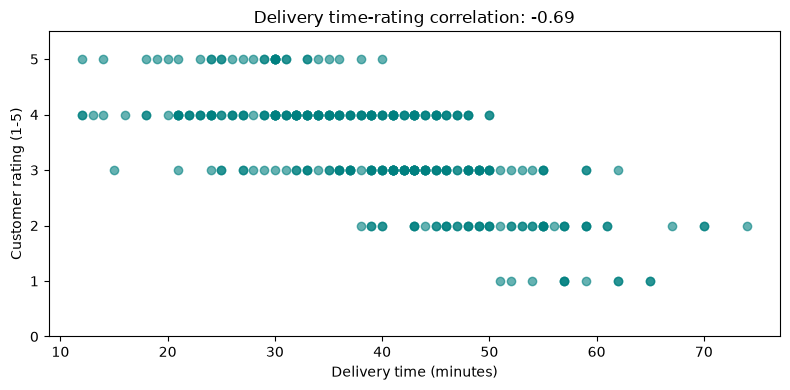

,المؤشر,القيمة
0,الارتباط,-0.690556
1,الطلبات المقيمة,340.000000


In [9]:
# نحلل طلبات التوصيل على مستوى رقم الطلب، مع إبقاء التقييمات المفقودة
delivery_orders = order_level.loc[
    order_level["channel"].eq("Delivery") & order_level["delivery_minutes"].notna()
].copy()
delivery_orders["delivery_group"] = pd.Series(index=delivery_orders.index, dtype="object")
delivery_orders.loc[delivery_orders["delivery_minutes"] < 30, "delivery_group"] = "<30 min"
delivery_orders.loc[delivery_orders["delivery_minutes"].between(30, 45, inclusive="both"), "delivery_group"] = "30-45 min"
delivery_orders.loc[delivery_orders["delivery_minutes"] > 45, "delivery_group"] = ">45 min"
group_order = ["<30 min", "30-45 min", ">45 min"]
delivery_orders["delivery_group"] = pd.Categorical(delivery_orders["delivery_group"], categories=group_order, ordered=True)
delivery_summary = delivery_orders.groupby("delivery_group", observed=False).agg(
    orders=("order_id", "nunique"),
    rated_orders=("rating", "count"),
    average_rating=("rating", "mean"),
    average_delivery_minutes=("delivery_minutes", "mean"),
)
print("التقييمات حسب مدة التوصيل (المفقود مستبعد من المتوسط فقط):")
display(delivery_summary.rename(index={"<30 min": "أقل من 30 دقيقة", "30-45 min": "من 30 إلى 45 دقيقة", ">45 min": "أكثر من 45 دقيقة"}, columns={
    "orders": "عدد الطلبات",
    "rated_orders": "طلبات بتقييم",
    "average_rating": "متوسط التقييم",
    "average_delivery_minutes": "متوسط مدة التوصيل (دقيقة)",
}).round(2))
rated_deliveries = delivery_orders.dropna(subset=["rating", "delivery_minutes"])
delivery_rating_correlation = rated_deliveries["delivery_minutes"].corr(rated_deliveries["rating"])
print(f"معامل ارتباط بيرسون بين مدة التوصيل والتقييم (على مستوى الطلب، {len(rated_deliveries)} طلبًا مقيمًا): {delivery_rating_correlation:.3f}")
relation_text = "ارتباط عكسي" if delivery_rating_correlation < 0 else "ارتباط طردي" if delivery_rating_correlation > 0 else "لا يظهر ارتباط خطي"
print(f"تفسير وصفي: {relation_text} بين زمن التوصيل والتقييم؛ الارتباط وحده لا يثبت السببية.")

# نرسم التقييمات الفردية لفحص اتجاه العلاقة
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(rated_deliveries["delivery_minutes"], rated_deliveries["rating"], alpha=0.6, color="teal")
ax.set_title(f"Delivery time-rating correlation: {delivery_rating_correlation:.2f}")
ax.set_xlabel("Delivery time (minutes)")
ax.set_ylabel("Customer rating (1-5)")
ax.set_ylim(0, 5.5)
plt.tight_layout()
plt.show()
display(pd.DataFrame({"المؤشر": ["الارتباط", "الطلبات المقيمة"], "القيمة": [delivery_rating_correlation, len(rated_deliveries)]}))


<div dir="rtl">

## الخطوة 5: التوصيات الإدارية (س6)
تُطبع التوصيات بعد تشغيل الخلايا السابقة، وتستند إلى المقاييس المحسوبة فقط. لا يُنشأ تقرير منفصل.

</div>

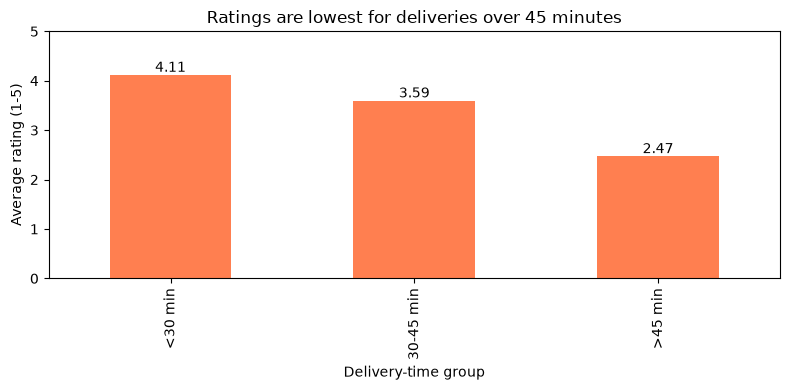

,عدد الطلبات,طلبات بتقييم,متوسط التقييم,متوسط مدة التوصيل (دقيقة)
delivery_group,,,,
أقل من 30 دقيقة,69,61,4.11,22.52
من 30 إلى 45 دقيقة,200,185,3.59,38.01
أكثر من 45 دقيقة,105,94,2.47,52.67


In [10]:
# نقارن متوسط التقييم بين فئات مدة التوصيل
fig, ax = plt.subplots(figsize=(8, 4))
delivery_summary["average_rating"].plot(kind="bar", ax=ax, color="coral")
ax.set_title("Ratings are lowest for deliveries over 45 minutes")
ax.set_xlabel("Delivery-time group")
ax.set_ylabel("Average rating (1-5)")
ax.set_ylim(0, 5)
for bar in ax.patches:
    ax.annotate(f"{bar.get_height():.2f}", (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.show()
display(delivery_summary.rename(index={"<30 min": "أقل من 30 دقيقة", "30-45 min": "من 30 إلى 45 دقيقة", ">45 min": "أكثر من 45 دقيقة"}, columns={
    "orders": "عدد الطلبات",
    "rated_orders": "طلبات بتقييم",
    "average_rating": "متوسط التقييم",
    "average_delivery_minutes": "متوسط مدة التوصيل (دقيقة)",
}).round(2))


In [11]:
# نبني توصيات قابلة للمراجعة باستخدام النتائج المحسوبة أعلاه
lowest_revenue_branch = branch_metrics["revenue"].idxmin()
highest_revenue_branch = branch_metrics["revenue"].idxmax()
busiest_hour = int(hour_counts.idxmax())
second_busiest_hour = int(hour_counts.sort_values(ascending=False).index[1])
busiest_weekday = weekday_counts.idxmax()
fast_rating = delivery_summary.loc["<30 min", "average_rating"]
slow_rating = delivery_summary.loc[">45 min", "average_rating"]

recommendations = [
    f"1. اختبر عروضًا أو حزمًا ترفع متوسط الفاتورة في فرع {lowest_revenue_branch}: إيراده {branch_metrics.loc[lowest_revenue_branch, 'revenue']:.2f} ومتوسط الطلب {branch_metrics.loc[lowest_revenue_branch, 'average_order_value']:.2f}، مقابل {branch_metrics.loc[highest_revenue_branch, 'revenue']:.2f} إيرادًا في {highest_revenue_branch}. قارن متوسط الفاتورة بعد التجربة بخط الأساس الحالي.",
    f"2. وزّع الطاقم والتحضير بما يتناسب مع الذروة؛ بلغ عدد الطلبات {int(hour_counts.loc[busiest_hour])} عند الساعة {busiest_hour}:00 و{int(hour_counts.loc[second_busiest_hour])} عند {second_busiest_hour}:00، وكان {weekday_names[busiest_weekday]} الأكثر ازدحامًا بـ{int(weekday_counts.loc[busiest_weekday])} طلبًا. قارن عدد الطلبات وفترات التأخير مستقبلًا بعد تغيير المناوبات.",
    f"3. راجع مراحل التوصيل التي تتجاوز 45 دقيقة: متوسط التقييم فيها {slow_rating:.2f} مقابل {fast_rating:.2f} للتوصيل الأقل من 30 دقيقة، وارتباط المدة بالتقييم {delivery_rating_correlation:.3f} عبر {len(rated_deliveries)} طلبًا مقيمًا؛ قارن متوسط زمن الفئة وتقييمها في المتابعة بخط الأساس، فالارتباط لا يثبت السببية.",
]
for recommendation in recommendations:
    print(recommendation)


1. اختبر عروضًا أو حزمًا ترفع متوسط الفاتورة في فرع University: إيراده 4140.00 ومتوسط الطلب 9.32، مقابل 7933.00 إيرادًا في Mall. قارن متوسط الفاتورة بعد التجربة بخط الأساس الحالي.
2. وزّع الطاقم والتحضير بما يتناسب مع الذروة؛ بلغ عدد الطلبات 220 عند الساعة 20:00 و216 عند 13:00، وكان السبت الأكثر ازدحامًا بـ280 طلبًا. قارن عدد الطلبات وفترات التأخير مستقبلًا بعد تغيير المناوبات.
3. راجع مراحل التوصيل التي تتجاوز 45 دقيقة: متوسط التقييم فيها 2.47 مقابل 4.11 للتوصيل الأقل من 30 دقيقة، وارتباط المدة بالتقييم -0.691 عبر 340 طلبًا مقيمًا؛ قارن متوسط زمن الفئة وتقييمها في المتابعة بخط الأساس، فالارتباط لا يثبت السببية.
